<a href="https://colab.research.google.com/github/kaorilivia-tech/Calculo-numerico/blob/main/Gauss_Seidel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<>:65: SyntaxWarning: invalid escape sequence '\i'
<>:65: SyntaxWarning: invalid escape sequence '\i'
/tmp/ipykernel_1643/2568633063.py:65: SyntaxWarning: invalid escape sequence '\i'
  ax2.set_ylabel('$||x^{(k)} - x^{(k-1)}||_{\infty}$')


k    | x          | y          | z          | ||x^(k) - x^(k-1)||_inf
-----------------------------------------------------------------
0    | 0.000000   | 0.000000   | 0.000000   | -                     
1    | 0.600000   | 2.054545   | -0.914545  | 2.054545e+00          
2    | 0.988364   | 2.006711   | -0.997002  | 3.883636e-01          
3    | 1.000071   | 2.000279   | -0.999986  | 1.170777e-02          
4    | 1.000025   | 2.000004   | -1.000005  | 2.755404e-04          
5    | 1.000001   | 2.000000   | -1.000000  | 2.389216e-05          
6    | 1.000000   | 2.000000   | -1.000000  | 1.262607e-06          

--- RESUMO ---
Número de iterações necessárias: 6
Solução aproximada obtida: x = 1.000000, y = 2.000000, z = -1.000000


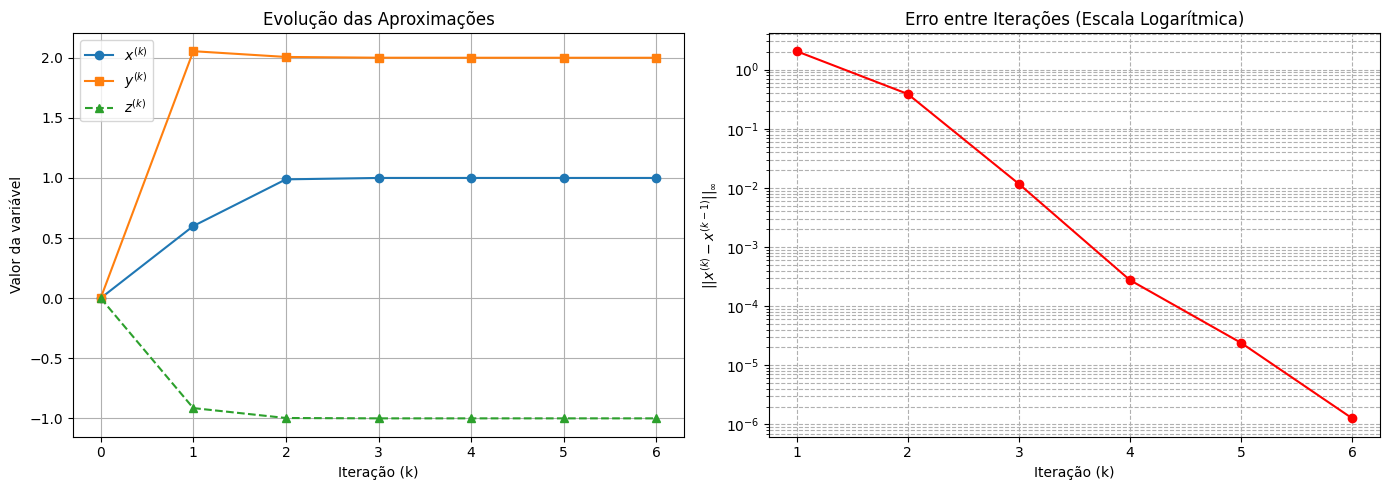

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


A = np.array([[10.0, -1.0, 2.0],
              [-1.0, 11.0, -1.0],
              [2.0, -1.0, 10.0]])

b = np.array([6.0, 22.0, -10.0])

x = np.array([0.0, 0.0, 0.0])
tol = 1e-5
max_iter = 100


history_x = [x.copy()]
errors = []

print(f"{'k':<4} | {'x':<10} | {'y':<10} | {'z':<10} | {'||x^(k) - x^(k-1)||_inf':<22}")
print("-" * 65)
print(f"{0:<4} | {x[0]:<10.6f} | {x[1]:<10.6f} | {x[2]:<10.6f} | {'-':<22}")

for k in range(1, max_iter + 1):
    x_old = x.copy()


    x[0] = (6.0 + x[1] - 2.0 * x[2]) / 10.0
    x[1] = (22.0 + x[0] + x[2]) / 11.0
    x[2] = (-10.0 - 2.0 * x[0] + x[1]) / 10.0


    err = np.max(np.abs(x - x_old))

    history_x.append(x.copy())
    errors.append(err)

    print(f"{k:<4} | {x[0]:<10.6f} | {x[1]:<10.6f} | {x[2]:<10.6f} | {err:<22.6e}")

    if err < tol:
        break

history_x = np.array(history_x)

print("\n--- RESUMO ---")
print(f"Número de iterações necessárias: {k}")
print(f"Solução aproximada obtida: x = {x[0]:.6f}, y = {x[1]:.6f}, z = {x[2]:.6f}")


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))


iters = np.arange(len(history_x))
ax1.plot(iters, history_x[:, 0], 'o-', label='$x^{(k)}$')
ax1.plot(iters, history_x[:, 1], 's-', label='$y^{(k)}$')
ax1.plot(iters, history_x[:, 2], '^--', label='$z^{(k)}$')
ax1.set_xlabel('Iteração (k)')
ax1.set_ylabel('Valor da variável')
ax1.set_title('Evolução das Aproximações')
ax1.grid(True)
ax1.legend()

ax2.semilogy(range(1, len(errors) + 1), errors, 'ro-')
ax2.set_xlabel('Iteração (k)')
ax2.set_ylabel('$||x^{(k)} - x^{(k-1)}||_{\infty}$')
ax2.set_title('Erro entre Iterações (Escala Logarítmica)')
ax2.grid(True, which="both", ls="--")

plt.tight_layout()
plt.show()